# Why the multi-k gamma method underestimates ANI on real genomes, and a fix

This notebook is **separate from the main project notebook** and does not modify it. It reads the same Drive files
(`data/genomes/*.fna`, `data/v2_*.csv`, `results/v2_exp5_raw.csv`) and writes everything new to `results/Part2/`.

**Sections**
1. Setup & shared code (original estimators copied unchanged + new estimators)
2. Near-threshold pairs (Mash 93–97 %) from genomes already downloaded
3. dnadiff reference + alignment coordinates for every pair
4. k-mer features per pair (k = 11–31, composition-matched background, 1 kb windows)
5. Real genomes: all estimators
6. Simulations scored against dnadiff (Exp 1–4 settings + real dnadiff, Mash, skani)
7. Figures

Every long step is resumable: results are saved per pair and skipped on re-run.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, sys, json, glob, shutil, subprocess, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    PROJECT = "/content/drive/MyDrive/CMPS355_ANI_Project"
    TOOLS = "/content/tools"
else:                                    # local test run
    PROJECT = os.environ.get("ANI_PROJECT", os.path.abspath("project"))
    TOOLS = os.environ.get("ANI_TOOLS", os.path.abspath("tools"))
DATA, RESULTS = f"{PROJECT}/data", f"{PROJECT}/results"
OUT = f"{RESULTS}/Part2"
GENOME_DIR = f"{DATA}/genomes"
FEAT_DIR, DD_DIR = f"{OUT}/features", f"{OUT}/dnadiff"
for d in [OUT, FEAT_DIR, DD_DIR, TOOLS]: os.makedirs(d, exist_ok=True)
QUICK = os.environ.get("ANI_QUICK") == "1"        # only for testing: tiny simulation
print("Project:", PROJECT)

Project: /content/drive/MyDrive/CMPS355_ANI_Project


In [3]:
# ---------------- tools: Mash, pyskani, MUMmer ----------------
subprocess.run("pip -q install pyskani", shell=True, check=True)
MASH_BIN = f"{TOOLS}/mash-Linux64-v2.3/mash"
if not os.path.exists(MASH_BIN):
    subprocess.run(f"cd {TOOLS} && wget -q https://github.com/marbl/Mash/releases/download/v2.3/mash-Linux64-v2.3.tar "
                   "&& tar -xf mash-Linux64-v2.3.tar", shell=True, check=True)
if shutil.which("dnadiff") is None:
    subprocess.run("apt-get -qq update > /dev/null && apt-get -qq install -y mummer > /dev/null", shell=True, check=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pyskani
from scipy.optimize import curve_fit
from scipy.special import gammainc
pd.set_option("display.width", 200)
print(subprocess.run([MASH_BIN, "--version"], capture_output=True, text=True).stdout.strip(), shutil.which("dnadiff"))

2.3 /usr/bin/dnadiff


## 1. Shared code
### Original method (copied unchanged from the main notebook)

In [4]:
KS = np.arange(15, 32, 2); K_MASH = 21

def est_mash(C, ks=KS):
    C21 = C[ks == K_MASH][0]; J = C21 / (2 - C21)
    return 1 + np.log(2 * J / (1 + J)) / K_MASH

def est_uniform(C, ks=KS):
    slope, intercept = np.polyfit(ks, np.log(C), 1)
    return np.exp(slope), np.exp(intercept), -slope

def gamma_model(k, s, d, alpha):
    return np.log(s) - alpha * np.log1p(k * d / alpha)

def est_gamma(C, ks=KS):
    y = np.log(C); _, s0, d0 = est_uniform(C, ks); best = None
    for a0 in [0.3, 1, 5, 50]:
        try:
            p, _ = curve_fit(gamma_model, ks, y, p0=[min(s0, 0.99), max(d0, 1e-4), a0],
                             bounds=([1e-6, 1e-6, 0.01], [1, 3, 1000]), maxfev=20000)
            err = np.sum((gamma_model(ks, *p) - y) ** 2)
            if best is None or err < best[1]: best = (p, err)
        except RuntimeError: pass
    s, d, alpha = best[0]
    return (1 + d / alpha) ** (-alpha), s, alpha

### New estimators
* **fit_gamma**: the same least-squares fit, optionally with s fixed or with per-point weights.
* **ani_gamma_aligned**: identity of only the regions whose local identity is above a cutoff q\* (what an aligner can align).
  Under the gamma model the region divergence λ ~ Gamma(α, d/α) and region identity = e^(−λ), so
  E[e^(−λ) | λ < λ\*] = (1 + d/α)^(−α) · P(Gamma(α, (d/α)/(1+d/α)) < λ\*) / P(Gamma(α, d/α) < λ\*), with λ\* = −ln q\*.
  The second number returned, P(λ < λ\*), is the predicted fraction of shared sequence that aligns.
* **Invariant-fraction model**: C(k) = s[π + (1−π)(1 + kd/α)^(−α)].
* q\* = 0.78 was calibrated on **simulations** (Section 6), not on the real genomes.

In [5]:
QSTAR = 0.78

def fit_gamma(ks, C, s_fixed=None, w=None):
    ks = np.asarray(ks, float); y = np.log(np.maximum(C, 1e-12)); sig = None if w is None else 1 / np.asarray(w)
    slope, inter = np.polyfit(ks, y, 1); s0, d0 = np.exp(inter), max(-slope, 1e-4); best = None
    for a0 in [0.3, 1, 5, 50]:
        try:
            if s_fixed is None:
                p, _ = curve_fit(gamma_model, ks, y, p0=[min(s0, 0.99), d0, a0], sigma=sig,
                                 bounds=([1e-6, 1e-6, 0.01], [1, 3, 1000]), maxfev=20000)
            else:
                f = lambda k, d, a: gamma_model(k, s_fixed, d, a)
                q, _ = curve_fit(f, ks, y, p0=[d0, a0], sigma=sig, bounds=([1e-6, 0.01], [3, 1000]), maxfev=20000)
                p = np.array([s_fixed, *q])
            r = gamma_model(ks, *p) - y
            if w is not None: r = r * w
            if best is None or np.sum(r**2) < best[1]: best = (p, np.sum(r**2))
        except (RuntimeError, ValueError): pass
    return best[0]                                     # s, d, alpha

def ani_gamma(d, a): return (1 + d / a) ** (-a)

def ani_gamma_aligned(d, a, qstar=QSTAR):
    lam, scale = -np.log(qstar), d / a
    p_al = gammainc(a, lam / scale)
    num = (1 + scale) ** (-a) * gammainc(a, lam * (1 + scale) / scale)
    return num / max(p_al, 1e-300), p_al

def inv_model(k, s, pi, d, a): return np.log(s) + np.log(pi + (1 - pi) * (1 + k * d / a) ** (-a))

def fit_inv(ks, C, s_fixed):
    ks = np.asarray(ks, float); y = np.log(np.maximum(C, 1e-12)); best = None
    for a0 in [0.5, 2, 10]:
        for pi0 in [0.01, 0.1, 0.3]:
            try:
                f = lambda k, pi, d, a: inv_model(k, s_fixed, pi, d, a)
                q, _ = curve_fit(f, ks, y, p0=[pi0, 0.05, a0], bounds=([0, 1e-6, 0.01], [0.999, 3, 1000]), maxfev=20000)
                sse = np.sum((f(ks, *q) - y) ** 2)
                if best is None or sse < best[1]: best = (q, sse)
            except (RuntimeError, ValueError): pass
    pi, d, a = best[0]
    return pi + (1 - pi) * ani_gamma(d, a)

### Fast canonical k-mer counting
Same canonical k-mers as the main notebook, but all k = 11…31 are built incrementally from k − 1, and duplicates are removed
with `np.sort` (on recent numpy `np.unique` is ~70× slower). Output is identical to `canonical_kmer_set`; about 30–60 s per pair.

Per pair (A = smaller genome) we save, for every k:
* distinct k-mers in A and B, and shared k-mers;
* **shared k-mers between A and the reversed (not complemented) B**: same base composition and repeat structure but no
  homology, i.e. a composition-matched chance-match background;
* per 1 kb window of A: number of valid k-mers and number shared with B.

In [6]:
LOOKUP = np.full(256, 4, dtype=np.uint8)
for i, b in enumerate(b"ACGT"): LOOKUP[b] = i
for i, b in enumerate(b"acgt"): LOOKUP[b] = i
KALL = np.arange(11, 32); WIN = 1000

def read_fasta(path):
    contigs, cur = [], []
    with open(path, "rb") as f:
        for line in f:
            if line.startswith(b">"):
                if cur: contigs.append(b"".join(cur)); cur = []
            else: cur.append(line.strip())
    if cur: contigs.append(b"".join(cur))
    return contigs

def encode(c): return LOOKUP[np.frombuffer(c, dtype=np.uint8)]

def uniq(a):
    a = np.sort(a)
    return a if a.size == 0 else a[np.concatenate([[True], a[1:] != a[:-1]])]

def member(sorted_set, v):
    idx = np.searchsorted(sorted_set, v); idx[idx >= sorted_set.size] = 0
    return sorted_set[idx] == v

class Roller:
    """canonical k-mers for k = 1, 2, ... built incrementally over a list of encoded contigs"""
    def __init__(self, enc):
        self.enc = enc; self.cb = [s & 3 for s in enc]
        self.cc = [(3 - (s & 3)).astype(np.uint64) for s in enc]
        self.bad = [np.concatenate([[0], np.cumsum(s == 4)]) for s in enc]
        self.f = [np.zeros(len(s), np.uint64) for s in enc]; self.r = [np.zeros(len(s), np.uint64) for s in enc]; self.k = 0
    def step(self):
        k = self.k
        for i, s in enumerate(self.enc):
            n = len(s) - k
            if n <= 0: self.f[i] = self.f[i][:0]; self.r[i] = self.r[i][:0]; continue
            self.f[i] = (self.f[i][:n] << np.uint64(2)) | self.cb[i][k:k + n].astype(np.uint64)
            self.r[i] = self.r[i][:n] | (self.cc[i][k:k + n] << np.uint64(2 * k))
        self.k += 1
    def get(self):
        k = self.k; vals, oks = [], []
        for i, s in enumerate(self.enc):
            if len(s) - k + 1 <= 0: vals.append(np.zeros(0, np.uint64)); oks.append(np.zeros(0, bool)); continue
            vals.append(np.minimum(self.f[i], self.r[i])); oks.append((self.bad[i][k:] - self.bad[i][:-k]) == 0)
        return vals, oks

def kmer_features(path_a, path_b, out):
    ca, cb = read_fasta(path_a), read_fasta(path_b)
    swapped = sum(map(len, ca)) > sum(map(len, cb))
    if swapped: ca, cb = cb, ca                                   # A = smaller genome (as in the main notebook)
    ea = [encode(c) for c in ca]; eb = [encode(c) for c in cb]
    eb_rev = [np.ascontiguousarray(s[::-1]) for s in eb]          # reversed, NOT complemented: background
    RA, RB, RR = Roller(ea), Roller(eb), Roller(eb_rev)
    for _ in range(KALL[0] - 1): RA.step(); RB.step(); RR.step()
    nA, nB, sh, shr, wv_all, ws_all = [], [], [], [], [], []
    for k in KALL:
        RA.step(); RB.step(); RR.step()
        va, oka = RA.get(); setA = uniq(np.concatenate([v[o] for v, o in zip(va, oka)]))
        vb, okb = RB.get(); setB = uniq(np.concatenate([v[o] for v, o in zip(vb, okb)]))
        vr, okr = RR.get(); setR = uniq(np.concatenate([v[o] for v, o in zip(vr, okr)]))
        nA.append(setA.size); nB.append(setB.size)
        sh.append(int(member(setB, setA).sum())); shr.append(int(member(setR, setA).sum()))
        wv, ws = [], []
        for v, o in zip(va, oka):                                  # windows never cross contigs
            hit = member(setB, v) & o; nwin = int(np.ceil(len(v) / WIN)) if len(v) else 0
            w = np.arange(len(v)) // WIN
            wv.append(np.bincount(w, weights=o, minlength=nwin)); ws.append(np.bincount(w, weights=hit, minlength=nwin))
        wv_all.append(np.concatenate(wv)); ws_all.append(np.concatenate(ws))
    m = min(map(len, wv_all))
    tmp = out[:-4] + ".tmp.npz"
    np.savez_compressed(tmp, ks=KALL, swapped=swapped, nA=nA, nB=nB, shared=sh, shared_rev=shr,
                        win_valid=np.array([w[:m] for w in wv_all]).astype(np.int32),
                        win_shared=np.array([w[:m] for w in ws_all]).astype(np.int32))
    os.replace(tmp, out)

## 2. Near-threshold pairs (Mash 93–97 %) from genomes already downloaded

In [7]:
genomes = pd.read_csv(f"{DATA}/v2_genomes.csv")
genomes["path"] = [f"{GENOME_DIR}/{a}.fna" for a in genomes.accession]
assert all(os.path.exists(p) for p in genomes.path), "some genomes are missing from data/genomes"
pairs_v2 = pd.read_csv(f"{DATA}/v2_pairs.csv").assign(batch="v2")
NEAR_FILE = f"{OUT}/near95_pairs.csv"
if os.path.exists(NEAR_FILE):
    near = pd.read_csv(NEAR_FILE); print("Loaded", NEAR_FILE)
else:
    used = set(zip(pairs_v2.acc_a, pairs_v2.acc_b)) | set(zip(pairs_v2.acc_b, pairs_v2.acc_a)); rows = []
    for grp, g in genomes.groupby("genus"):
        tag = f"/tmp/mash_{grp.split()[0]}"
        subprocess.run([MASH_BIN, "sketch", "-k", "21", "-s", "10000", "-o", tag, *g.path], capture_output=True, check=True)
        out = subprocess.run([MASH_BIN, "dist", tag + ".msh", tag + ".msh"], capture_output=True, text=True, check=True).stdout
        dist = {(l.split("\t")[0], l.split("\t")[1]): 1 - float(l.split("\t")[2]) for l in out.splitlines()}
        recs = g.to_dict("records")
        cand = sorted([(dist[(recs[i]["path"], recs[j]["path"])], recs[i], recs[j])
                       for i in range(len(recs)) for j in range(i + 1, len(recs))
                       if 0.93 <= dist[(recs[i]["path"], recs[j]["path"])] <= 0.97
                       and (recs[i]["accession"], recs[j]["accession"]) not in used], key=lambda c: c[0])
        if len(cand) > 8:
            cand = [cand[i] for i in np.unique(np.linspace(0, len(cand) - 1, 8).round().astype(int))]
        rows += [{"genus": grp, "acc_a": a["accession"], "acc_b": b["accession"], "species_a": a["species"],
                  "species_b": b["species"], "path_a": a["path"], "path_b": b["path"], "mash_tool": m, "batch": "near95"}
                 for m, a, b in cand]
    near = pd.DataFrame(rows); near.to_csv(NEAR_FILE, index=False)
print(near.groupby("genus").size().to_string())
pairs = pd.concat([pairs_v2, near], ignore_index=True)
pairs["path_a"] = [f"{GENOME_DIR}/{a}.fna" for a in pairs.acc_a]; pairs["path_b"] = [f"{GENOME_DIR}/{b}.fna" for b in pairs.acc_b]
print("total pairs:", len(pairs))

Loaded /content/drive/MyDrive/CMPS355_ANI_Project/results/Part2/near95_pairs.csv
genus
Bacillus cereus group        2
Escherichia                  7
Klebsiella                   8
Streptococcus mitis group    8
total pairs: 85


## 3. dnadiff for every pair (same call as the main notebook), keeping the 1-to-1 alignment coordinates
For the 60 original pairs this reproduces `v2_reference_ani.csv` exactly; it is re-run only to keep the `.1coords` files.

In [8]:
def parse_report(path):
    ani = al1 = al2 = None; one = False
    for line in open(path):
        if line.startswith("AlignedBases") and al1 is None:
            p = line.split(); al1 = float(p[1].split("(")[1].rstrip("%)")) / 100; al2 = float(p[2].split("(")[1].rstrip("%)")) / 100
        if line.startswith("1-to-1"): one = True
        if one and line.startswith("AvgIdentity"): ani = float(line.split()[1]) / 100; break
    return ani, al1, al2

refs = []
for n, p in enumerate(pairs.itertuples(), 1):
    pre = f"{DD_DIR}/{p.acc_a}__{p.acc_b}"
    if not os.path.exists(pre + ".report"):
        subprocess.run(["dnadiff", "-p", "/tmp/dd", p.path_a, p.path_b], capture_output=True, check=True)
        for ext in [".report", ".1coords"]: shutil.copy("/tmp/dd" + ext, pre + ext)
        print(f"[{n}/{len(pairs)}] dnadiff done", flush=True)
    ani, a1, a2 = parse_report(pre + ".report")
    refs.append({"acc_a": p.acc_a, "acc_b": p.acc_b, "ref_ani": ani, "aligned_a": a1, "aligned_b": a2})
refs = pd.DataFrame(refs)
old = pd.read_csv(f"{DATA}/v2_reference_ani.csv").merge(refs, on=["acc_a", "acc_b"], suffixes=("", "_new"))
print("check vs saved reference, max |diff|:", (old.ref_ani - old.ref_ani_new).abs().max())

check vs saved reference, max |diff|: 1.1102230246251565e-16


## 4. k-mer features for every pair (resumable)

In [9]:
import time
for n, p in enumerate(pairs.itertuples(), 1):
    out = f"{FEAT_DIR}/{p.acc_a}__{p.acc_b}.npz"
    if os.path.exists(out): continue
    t = time.time(); kmer_features(p.path_a, p.path_b, out)
    print(f"[{n}/{len(pairs)}] {p.genus}: {p.species_a} vs {p.species_b}  {time.time() - t:.0f}s", flush=True)
print("features:", len(glob.glob(f"{FEAT_DIR}/*.npz")))

features: 85


## 5. Real genomes: every estimator on every pair
| Label | Estimator |
|---|---|
| original | multi-k gamma, chance correction as in the main notebook |
| A | + composition-matched background (reversed B) instead of the uniform-chance formula |
| B | + count-weighted fit (weights ∝ √shared k-mers) |
| C | s fixed = fraction of A's 1 kb windows with ≥ 1 shared 21-mer above background (the planned "fifth estimator") |
| D | C + invariant fraction π |
| E | non-parametric: per-window identity from the k = 17–25 shared fractions, averaged over windows above q\* |
| F | original fit, but report identity of regions above q\* (aligned-only target) |
| **G** | **C + F: window s, then aligned-only target** |

In [10]:
KS9 = KS

def curves(F):
    ks = F["ks"]; nA, nB, sh, shr = [F[x].astype(float) for x in ["nA", "nB", "shared", "shared_rev"]]
    nb = np.maximum(sh - nA * nB / (4.0 ** ks / 2), 1) / nA                 # main-notebook correction
    bg = shr / nA                                                         # empirical background
    emp = np.maximum((sh / nA - bg) / (1 - bg), 1 / nA)
    return ks, nb, bg, emp

def window_identity(F, bg, ks_use=(17, 19, 21, 23, 25)):
    ks = F["ks"]; idx = [np.where(ks == k)[0][0] for k in ks_use]
    v = F["win_valid"][idx].astype(float); h = np.maximum(F["win_shared"][idx] - v * bg[idx][:, None], 0)
    kk = np.array(ks_use, float)[:, None, None]; grid = np.linspace(0.5, 1, 501)[None, None, :]
    p = np.clip(grid ** kk, 1e-12, 1 - 1e-12)
    ll = (h[..., None] * np.log(p) + (v - h)[..., None] * np.log(1 - p)).sum(0)
    return grid[0, 0, ll.argmax(1)], v[0]

def all_estimators(F):
    ks, nb, bg, emp = curves(F); m9 = np.isin(ks, KS9); k9 = ks[m9]; c = nb[m9]; ce = emp[m9]
    o = {}
    o["Mash formula"] = est_mash(c, k9); o["uniform (control)"] = est_uniform(c, k9)[0]
    g, o["s_orig"], o["alpha_orig"] = est_gamma(c, k9); o["original"] = g
    s, d, a = fit_gamma(k9, ce); o["A: + empirical background"] = ani_gamma(d, a)
    n = F["shared"][m9].astype(float); s, d, a = fit_gamma(k9, c, w=np.sqrt(np.maximum(n, 1) / n.max()))
    o["B: + weighted fit"] = ani_gamma(d, a)
    i21 = np.where(ks == 21)[0][0]; V = F["win_valid"][i21]; H = F["win_shared"][i21]; ok = V >= 500
    sw = ((H >= 1 + V * bg[i21]) & ok).sum() / ok.sum(); o["s_window"] = sw
    s, d, a = fit_gamma(k9, c, s_fixed=min(sw, 1)); o["C: window s"] = ani_gamma(d, a)
    o["G: window s + aligned-only"], p_al = ani_gamma_aligned(d, a); o["pred_aligned"] = sw * p_al
    o["D: window s + invariant"] = fit_inv(k9, c, min(sw, 1))
    q, v = window_identity(F, bg); mm = (v > 500) & (q > QSTAR)
    o["E: per-window identity"] = np.average(q[mm], weights=v[mm])
    s, d, a = fit_gamma(k9, c); o["F: aligned-only"] = ani_gamma_aligned(d, a)[0]
    return o

old_tools = pd.read_csv(f"{RESULTS}/v2_exp5_raw.csv")[["acc_a", "acc_b", "skani"]]
rows = []
for p in pairs.merge(refs, on=["acc_a", "acc_b"]).itertuples():
    F = dict(np.load(f"{FEAT_DIR}/{p.acc_a}__{p.acc_b}.npz"))
    hit = old_tools[(old_tools.acc_a == p.acc_a) & (old_tools.acc_b == p.acc_b)]
    if len(hit): sk = hit.skani.values[0]
    else:                                                     # new pairs: skani exactly as in the main notebook
        ca, cb = read_fasta(p.path_a), read_fasta(p.path_b)
        if sum(map(len, ca)) > sum(map(len, cb)): ca, cb = cb, ca
        db = pyskani.Database(); db.sketch("A", *ca); h = db.query("B", *cb); sk = h[0].identity if h else np.nan
    r = dict(genus=p.genus, batch=p.batch, acc_a=p.acc_a, acc_b=p.acc_b, species_a=p.species_a, species_b=p.species_b,
             ref=p.ref_ani, aligned_a=p.aligned_a, aligned_b=p.aligned_b, aligned_A=p.aligned_b if F["swapped"] else p.aligned_a,
             **{"Mash (tool)": p.mash_tool, "skani": sk}, **all_estimators(F))
    rows.append(r)
real = pd.DataFrame(rows)
real["valid"] = real.ref.between(0.80, 0.99) & (real[["aligned_a", "aligned_b"]].min(axis=1) >= 0.5) & real.skani.notna()
real.to_csv(f"{OUT}/real_all_estimators.csv", index=False)

EST = ["Mash (tool)", "skani", "uniform (control)", "original", "A: + empirical background", "B: + weighted fit",
       "C: window s", "D: window s + invariant", "E: per-window identity", "F: aligned-only", "G: window s + aligned-only"]
def summary(d, est=EST):
    out = []
    for e in est:
        err = (d[e] - d.ref) * 100
        mis = (((d.ref < 0.95) & (d[e] >= 0.95)) | ((d.ref >= 0.95) & (d[e] < 0.95))).sum()
        out.append({"estimator": e, "n": len(d), "mean error": err.mean(), "mean |error|": err.abs().mean(),
                    "max |error|": err.abs().max(), "misclassified": mis})
    return pd.DataFrame(out).round(2)
v = real[real.valid]
print(f"Valid pairs (80-99% ANI, >=50% aligned): {len(v)} of {len(real)}")
summary(v)

Valid pairs (80-99% ANI, >=50% aligned): 73 of 85


,estimator,n,mean error,mean |error|,max |error|,misclassified
0,Mash (tool),73,0.30,0.37,1.05,6
1,skani,73,-0.50,0.53,2.61,0
2,uniform (control),73,3.05,3.05,6.76,42
3,original,73,-2.11,2.27,7.86,0
4,A: + empirical background,73,-2.07,2.31,7.96,0
5,B: + weighted fit,73,-2.02,2.18,8.03,0
6,C: window s,73,-0.66,0.71,2.73,0
7,D: window s + invariant,73,0.01,0.57,1.86,4
8,E: per-window identity,73,0.49,0.49,0.82,8
9,F: aligned-only,73,-0.46,0.66,1.39,0


In [11]:
v = real[real.valid].assign(bin=pd.cut(real.ref, [0.80, 0.88, 0.92, 0.95, 0.97, 0.99]))
key = ["Mash (tool)", "skani", "original", "G: window s + aligned-only"]
print("Mean error (ANI points) by reference-ANI bin")
print(v.groupby("bin").apply(lambda x: pd.Series({e: ((x[e] - x.ref) * 100).mean() for e in key} | {"n": len(x)})).round(2).to_string())
print("\nMean |error| by group")
print(v.groupby("genus").apply(lambda x: pd.Series({e: ((x[e] - x.ref) * 100).abs().mean() for e in key})).round(2).to_string())
print("\nNear threshold (reference 93-97%)"); print(summary(v[v.ref.between(0.93, 0.97)], key).to_string(index=False))
print("\nExcluded pairs (<50% aligned or ANI > 99%)"); print(summary(real[~real.valid], key).to_string(index=False))
print("\nModel-predicted aligned fraction vs dnadiff aligned fraction: r =",
      round(np.corrcoef(v.pred_aligned, v.aligned_A)[0, 1], 3))

Mean error (ANI points) by reference-ANI bin
              Mash (tool)  skani  original  G: window s + aligned-only     n
bin                                                                         
(0.8, 0.88]          0.12  -1.07     -3.91                        1.08   4.0
(0.88, 0.92]         0.32  -1.08     -4.99                        0.12  18.0
(0.92, 0.95]         0.39  -0.31     -1.31                       -0.09  40.0
(0.95, 0.97]         0.03   0.11     -0.81                       -0.03   2.0
(0.97, 0.99]        -0.03  -0.04      0.58                       -0.17   9.0

Mean |error| by group
                           Mash (tool)  skani  original  G: window s + aligned-only
genus                                                                              
Bacillus cereus group             0.47   0.24      1.14                        0.20
Escherichia                       0.40   0.53      3.77                        0.08
Klebsiella                        0.38   0.36      1.94  

In [12]:
# robustness: cutoff q* and held-out-genus check for G
def est_G(F, qstar, K=21, t=1):
    ks, nb, bg, emp = curves(F); m9 = np.isin(ks, KS9)
    i = np.where(ks == K)[0][0]; V = F["win_valid"][i]; H = F["win_shared"][i]; ok = V >= 500
    sw = ((H >= t + V * bg[i]) & ok).sum() / ok.sum()
    s, d, a = fit_gamma(ks[m9], nb[m9], s_fixed=min(sw, 1)); return ani_gamma_aligned(d, a, qstar)[0]
Fs = {(p.acc_a, p.acc_b): dict(np.load(f"{FEAT_DIR}/{p.acc_a}__{p.acc_b}.npz")) for p in v.itertuples()}
rob = []
for q in [0.74, 0.76, 0.78, 0.80, 0.82]:
    e = np.array([est_G(Fs[(p.acc_a, p.acc_b)], q) for p in v.itertuples()])
    err = (e - v.ref.values) * 100
    rob.append({"q*": q, "mean error": err.mean(), "mean |error|": np.abs(err).mean(),
                "misclassified": (((v.ref < 0.95) & (e >= 0.95)) | ((v.ref >= 0.95) & (e < 0.95))).sum()})
print("Sensitivity to the cutoff q*:"); print(pd.DataFrame(rob).round(3).to_string(index=False))
grid = {(K, t): np.array([est_G(Fs[(p.acc_a, p.acc_b)], QSTAR, K, t) for p in v.itertuples()]) for K in [17, 19, 21, 25] for t in [1, 2, 3, 5]}
cv = []
for g in v.genus.unique():
    tr, te = (v.genus != g).values, (v.genus == g).values
    best = min(grid, key=lambda kt: np.abs(grid[kt][tr] - v.ref.values[tr]).mean())
    cv.append({"held-out": g, "n": te.sum(), "chosen (k, min hits)": best,
               "held-out mean |error|": np.abs(grid[best][te] - v.ref.values[te]).mean() * 100})
cv = pd.DataFrame(cv); print("\nLeave-one-group-out:"); print(cv.round(3).to_string(index=False))
print("pooled:", round(np.average(cv["held-out mean |error|"], weights=cv.n), 3))

Sensitivity to the cutoff q*:
  q*  mean error  mean |error|  misclassified
0.74      -0.266         0.348              0
0.76      -0.141         0.275              0
0.78       0.021         0.218              0
0.80       0.228         0.350              0
0.82       0.490         0.555              1

Leave-one-group-out:
                 held-out  n chosen (k, min hits)  held-out mean |error|
    Bacillus cereus group 11              (19, 3)                  0.194
              Escherichia 21              (19, 2)                  0.126
               Klebsiella 18              (19, 5)                  0.371
Streptococcus mitis group 23              (19, 3)                  0.249
pooled: 0.235


## 6. Simulations scored against dnadiff
Same simulator and settings as Experiments 1–4 (1 Mb random genome, 5 kb regions), 20 pairs per setting.
For every pair we also run **dnadiff, Mash and skani**, so each estimator can be scored against both the true ANI and dnadiff.
This is also where q\* is calibrated: the identity cutoff at which "mean identity of regions above q\*" equals dnadiff's ANI.

In [13]:
GENOME_LEN, REGION_LEN = 1_000_000, 5_000; N_REGIONS = GENOME_LEN // REGION_LEN
DEC = np.frombuffer(b"ACGT", dtype=np.uint8)
rng = np.random.default_rng(42)
def rates_uniform(n): return np.ones(n)
def rates_gamma(alpha): return lambda n: rng.gamma(alpha, 1 / alpha, n)
def rates_two_class(n, frac_fast=0.3, fold=5):
    r = np.where(rng.random(n) < frac_fast, fold, 1.0); return r / r.mean()
def rates_wave(n, fold=4, waves=2):
    x = np.arange(n) / n; amp = (fold - 1) / (fold + 1)
    r = 1 + amp * np.sin(2 * np.pi * waves * x + rng.uniform(0, 2 * np.pi)); return r / r.mean()
def make_pair(mean_p, rate_fn, gene_diff=0.0):
    rates = rate_fn(N_REGIONS)
    p_site = np.clip(np.repeat(mean_p * rates, REGION_LEN), 0, 0.75)
    hit = rng.random(GENOME_LEN) < p_site
    B = genome_A.copy(); B[hit] = (genome_A[hit] + rng.integers(1, 4, hit.sum())) % 4
    replaced = rng.choice(N_REGIONS, int(round(gene_diff * N_REGIONS)), replace=False)
    is_rep = np.isin(np.arange(GENOME_LEN) // REGION_LEN, replaced)
    B[is_rep] = rng.integers(0, 4, is_rep.sum(), dtype=np.uint8)
    return B, 1 - hit[~is_rep].mean(), hit, is_rep
def pack_fwd(seq, k):
    n = len(seq) - k + 1; vals = np.zeros(n, dtype=np.uint64)
    for j in range(k): vals = (vals << np.uint64(2)) | seq[j:j + n].astype(np.uint64)
    return vals
def kmer_set(seq, k): return uniq(pack_fwd(seq, k))
def wfa(path, seq):
    with open(path, "wb") as f: f.write(b">seq\n" + DEC[seq].tobytes() + b"\n")

genome_A = rng.integers(0, 4, GENOME_LEN, dtype=np.uint8)
kA = {k: kmer_set(genome_A, k) for k in KS}; A21 = pack_fwd(genome_A, 21)
SIMD = "/tmp/simdd"; os.makedirs(SIMD, exist_ok=True); wfa(f"{SIMD}/A.fa", genome_A)
subprocess.run([MASH_BIN, "sketch", "-k", "21", "-s", "10000", "-o", f"{SIMD}/A", f"{SIMD}/A.fa"], capture_output=True, check=True)
skdb = pyskani.Database(); skdb.sketch("A", DEC[genome_A].tobytes())

SIM_FILE = f"{OUT}/sim_vs_dnadiff{'_quick' if QUICK else ''}.csv"
SIM_SETTINGS = {"Gamma a=2": (rates_gamma(2.0), 0.0), "Gamma a=0.5": (rates_gamma(0.5), 0.0),
                "Two-class": (rates_two_class, 0.0), "Gamma a=2 + 30% unique": (rates_gamma(2.0), 0.3),
                "Uniform": (rates_uniform, 0.0), "Wave": (rates_wave, 0.0)}
TARGETS = np.arange(0.80, 0.99, 0.02) if not QUICK else np.array([0.82, 0.96])
rng = np.random.default_rng(11)
if os.path.exists(SIM_FILE):
    sim = pd.read_csv(SIM_FILE); print("Loaded", SIM_FILE)
else:
    rows = []
    for name, (fn, gd) in SIM_SETTINGS.items():
        print("Running:", name, flush=True)
        for target in TARGETS:
            for rep in range(2):
                B, true_ani, hit, is_rep = make_pair(1 - target, fn, gd)
                C = []
                for k in KS:
                    kB = kmer_set(B, k); sh = member(kB, kA[k]).sum()
                    C.append(max(sh - kA[k].size * kB.size / 4.0 ** k, 1) / kA[k].size)
                C = np.array(C)
                sB = kmer_set(B, 21); w = np.bincount(np.arange(A21.size) // 1000, weights=member(sB, A21))
                sw = (w >= 1).mean()
                wfa(f"{SIMD}/B.fa", B)
                subprocess.run(["dnadiff", "-p", f"{SIMD}/dd", f"{SIMD}/A.fa", f"{SIMD}/B.fa"], capture_output=True, check=True)
                dd_ani, dd_al, _ = parse_report(f"{SIMD}/dd.report")
                mash = 1 - float(subprocess.run([MASH_BIN, "dist", f"{SIMD}/A.msh", f"{SIMD}/B.fa"], capture_output=True,
                                                text=True, check=True).stdout.split("\t")[2])
                h = skdb.query("B", DEC[B].tobytes())
                reg = np.arange(GENOME_LEN) // REGION_LEN
                rid = (1 - np.bincount(reg, weights=hit) / REGION_LEN)[np.bincount(reg, weights=is_rep) == 0]
                s, d, a = fit_gamma(KS, C); sG, dG, aG = fit_gamma(KS, C, s_fixed=min(sw, 1))
                rows.append({"setting": name, "target": target, "true": true_ani, "dnadiff": dd_ani, "dnadiff_aligned": dd_al,
                             "Mash (tool)": mash, "skani": h[0].identity if h else np.nan,
                             "original": est_gamma(C)[0], "F: aligned-only": ani_gamma_aligned(d, a)[0],
                             "C: window s": ani_gamma(dG, aG), "G: window s + aligned-only": ani_gamma_aligned(dG, aG)[0],
                             "region_identity": json.dumps(np.round(rid, 4).tolist())})
    sim = pd.DataFrame(rows); sim.to_csv(SIM_FILE, index=False)

SIM_EST = ["Mash (tool)", "skani", "original", "F: aligned-only", "C: window s", "G: window s + aligned-only"]
for tgt in ["dnadiff", "true"]:
    print(f"\nMean |error| vs {tgt} (ANI points)")
    print(pd.DataFrame({e: ((sim[e] - sim[tgt]) * 100).abs().groupby(sim.setting, sort=False).mean() for e in SIM_EST}).round(2).to_string())
    print(f"Misclassified at 95% vs {tgt}")
    print(pd.DataFrame({e: (((sim[tgt] < .95) & (sim[e] >= .95)) | ((sim[tgt] >= .95) & (sim[e] < .95))).groupby(sim.setting, sort=False).sum()
                        for e in SIM_EST}).to_string())

Loaded /content/drive/MyDrive/CMPS355_ANI_Project/results/Part2/sim_vs_dnadiff.csv

Mean |error| vs dnadiff (ANI points)
                        Mash (tool)  skani  original  F: aligned-only  C: window s  G: window s + aligned-only
setting                                                                                                       
Gamma a=2                      1.22   0.52      1.66             0.33         0.70                        0.47
Gamma a=0.5                    1.29   0.52      3.05             0.37         0.95                        0.57
Two-class                      1.60   1.66      0.89             0.89         0.33                        0.37
Gamma a=2 + 30% unique         0.84   1.86      1.55             0.26         0.77                        0.20
Uniform                        0.78   0.60      0.15             0.12         0.06                        0.06
Wave                           1.02   0.44      0.34             0.31         0.64                    

In [14]:
# calibration of q*: for each pair, the cutoff at which mean identity of regions above it equals dnadiff's ANI
qs = np.linspace(0.6, 0.95, 351); cal = []
for r in sim.itertuples():
    rid = np.array(json.loads(r.region_identity))
    if rid.min() > 0.80: continue                       # no regions near the cutoff: uninformative
    m = np.array([rid[rid > q].mean() for q in qs])
    cal.append({"setting": r.setting, "true": r.true, "dnadiff": r.dnadiff, "q*": qs[np.argmin(np.abs(m - r.dnadiff))],
                "dnadiff - true": (r.dnadiff - r.true) * 100})
cal = pd.DataFrame(cal)
print("Implied dnadiff cutoff q*: median", round(float(cal["q*"].median()), 3),
      " IQR", [round(float(x), 3) for x in cal["q*"].quantile([.25, .75])])
print(cal.groupby("setting", sort=False)[["q*", "dnadiff - true"]].median().round(3).to_string())

Implied dnadiff cutoff q*: median 0.778  IQR [0.766, 0.812]
                           q*  dnadiff - true
setting                                      
Gamma a=2               0.772           2.308
Gamma a=0.5             0.764           5.091
Two-class               0.923           7.845
Gamma a=2 + 30% unique  0.787           2.898
Uniform                 0.818           0.340
Wave                    0.935           4.142


## 7. Figures

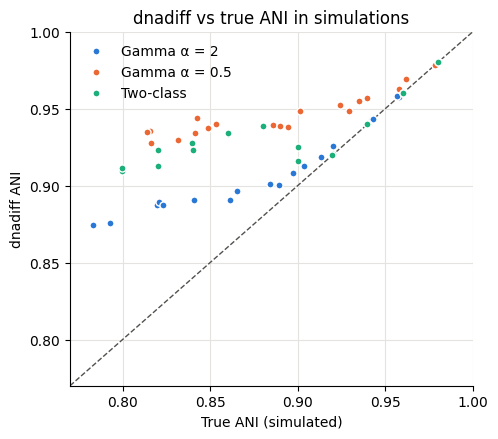

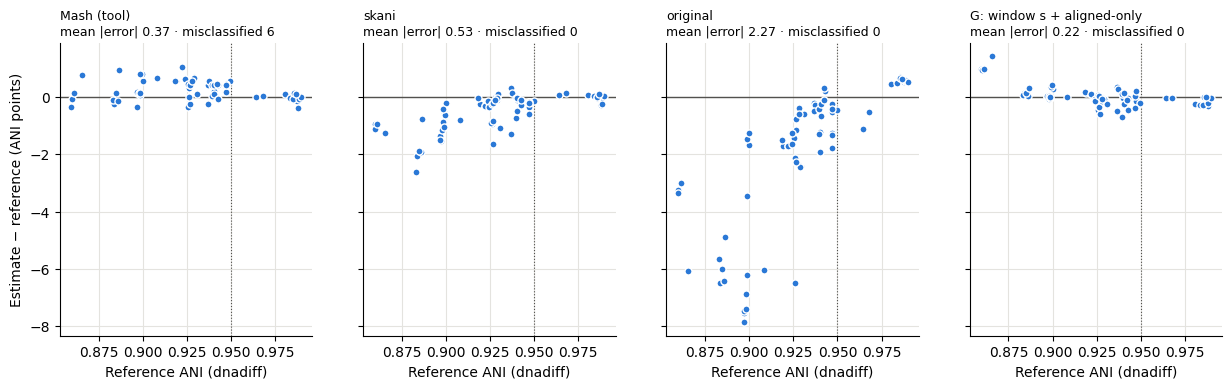

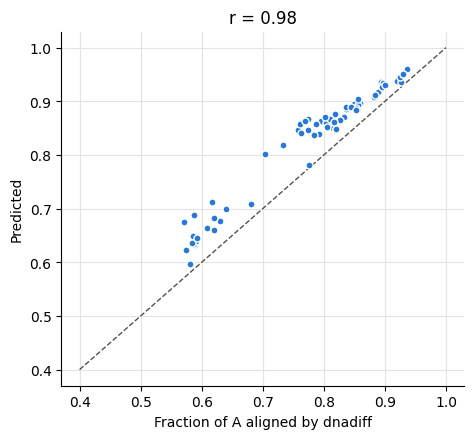

In [15]:
S1, S2, S3, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID})
def dot(ax, x, y, c, label=None): ax.scatter(x, y, s=26, color=c, edgecolor="white", linewidth=1, zorder=3, label=label)

fig, ax = plt.subplots(figsize=(5.2, 4.6))
for (s, lab), c in zip([("Gamma a=2", "Gamma α = 2"), ("Gamma a=0.5", "Gamma α = 0.5"), ("Two-class", "Two-class")], [S1, S2, S3]):
    d = sim[sim.setting == s]; dot(ax, d.true, d.dnadiff, c, lab)
ax.plot([.77, 1], [.77, 1], "--", color=INK2, lw=1); ax.set_xlim(.77, 1); ax.set_ylim(.77, 1)
ax.set(xlabel="True ANI (simulated)", ylabel="dnadiff ANI", title="dnadiff vs true ANI in simulations"); ax.legend(frameon=False)
plt.savefig(f"{OUT}/fig1_dnadiff_vs_true.png", dpi=200, bbox_inches="tight"); plt.show()

v = real[real.valid]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, e in zip(axes, ["Mash (tool)", "skani", "original", "G: window s + aligned-only"]):
    err = (v[e] - v.ref) * 100; dot(ax, v.ref, err, S1); ax.axhline(0, color=INK2, lw=1); ax.axvline(.95, color=INK2, lw=.8, ls=":")
    mis = (((v.ref < .95) & (v[e] >= .95)) | ((v.ref >= .95) & (v[e] < .95))).sum()
    ax.set_title(f"{e}\nmean |error| {err.abs().mean():.2f} · misclassified {mis}", fontsize=9, loc="left"); ax.set_xlabel("Reference ANI (dnadiff)")
axes[0].set_ylabel("Estimate − reference (ANI points)")
plt.savefig(f"{OUT}/fig2_real_errors.png", dpi=200, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(5.2, 4.6))
dot(ax, v.aligned_A, v.pred_aligned, S1, "Model-predicted aligned fraction")
ax.plot([.4, 1], [.4, 1], "--", color=INK2, lw=1)
ax.set(xlabel="Fraction of A aligned by dnadiff", ylabel="Predicted", title=f"r = {np.corrcoef(v.aligned_A, v.pred_aligned)[0,1]:.2f}")
plt.savefig(f"{OUT}/fig3_aligned_fraction.png", dpi=200, bbox_inches="tight"); plt.show()

## 8. Multi-tool test: does G predict other aligners, using only a cutoff calibrated on simulations?

G has one setting: the identity cutoff q* below which an aligner stops counting regions (0.78 for dnadiff, calibrated on simulations). If G only works because it was tuned to dnadiff, it should not predict other reference tools. If the model really captures how rates vary along real genomes, then G with each tool's own q* (calibrated on simulations only) should predict that tool's ANI on real genomes.

**Reference tools:** dnadiff; nucmer -l15 (dnadiff on a more sensitive nucmer run: 15-letter anchors, clusters ≥ 40); ANIb (BLAST, as in pyani); FastANI v1.34.

**Steps:** (1) run the extra tools on the simulated pairs of Section 6; (2) calibrate q* per tool and freeze the predictions and pass criteria in `predictions.json` before any real genome is used; (3) choose new held-out real pairs (seed 2026); (4) run all tools on the 73 development pairs and the held-out pairs; (5) score and check the frozen criteria. The held-out pairs are the primary test. Everything is written to `results/multitool/`.

In [16]:
import time
OUT2 = f"{RESULTS}/multitool"
for d in [OUT2, f"{OUT2}/dnadiff", f"{OUT2}/features"]: os.makedirs(d, exist_ok=True)
WT = "/tmp/mt"; os.makedirs(WT, exist_ok=True)                 # temporary files (not on Drive)
NCPU = os.cpu_count() or 2

if shutil.which("blastn") is None:
    subprocess.run("apt-get -qq update > /dev/null && apt-get -qq install -y ncbi-blast+ > /dev/null", shell=True, check=True)
FASTANI_BIN = f"{TOOLS}/fastANI"
if not os.path.exists(FASTANI_BIN):
    subprocess.run(f"cd {TOOLS} && wget -q https://github.com/ParBLiSS/FastANI/releases/download/v1.34/fastANI-linux64-v1.34.zip "
                   "&& unzip -o -q fastANI-linux64-v1.34.zip", shell=True, check=True)
subprocess.run(["chmod", "+x", FASTANI_BIN])

def smaller_first(fa1, fa2):
    """(query, other): the smaller genome is the query, as for the k-mer methods"""
    return (fa1, fa2) if sum(map(len, read_fasta(fa1))) <= sum(map(len, read_fasta(fa2))) else (fa2, fa1)

def tool_nucmer_sensitive(fa_a, fa_b, tag):
    """dnadiff on a more sensitive nucmer run: anchors of 15 letters (default 20), clusters >= 40 (default 65)"""
    pre = f"{WT}/{tag}"
    subprocess.run(["nucmer", "--maxmatch", "-l", "15", "-c", "40", "-p", pre, fa_a, fa_b], capture_output=True, check=True)
    subprocess.run(["dnadiff", "-d", pre + ".delta", "-p", pre + "_dd"], capture_output=True, check=True)
    return parse_report(pre + "_dd.report")[0]

ANIB_FRAG = 1020
def tool_anib(fa_q, fa_db, tag):
    """ANIb as in pyani: 1020-nt fragments of the query, blastn -task blastn against the other genome;
    keep each fragment's best hit with > 70% of the fragment aligned and > 30% identity over the fragment;
    ANI = mean BLAST percent identity of the kept hits."""
    frag, db, out = f"{WT}/{tag}_frag.fna", f"{WT}/{tag}_db", f"{WT}/{tag}_blast.tab"
    with open(frag, "wb") as f:
        n = 0
        for c in read_fasta(fa_q):
            for i in range(0, len(c), ANIB_FRAG):
                f.write(b">f%d\n" % n + c[i:i + ANIB_FRAG] + b"\n"); n += 1
    subprocess.run(["makeblastdb", "-in", fa_db, "-dbtype", "nucl", "-out", db], capture_output=True, check=True)
    subprocess.run(["blastn", "-query", frag, "-db", db, "-out", out, "-task", "blastn", "-xdrop_gap_final", "150",
                    "-dust", "no", "-evalue", "1e-15", "-max_target_seqs", "1", "-num_threads", str(NCPU),
                    "-outfmt", "6 qseqid sseqid length mismatch pident gaps qlen bitscore"], capture_output=True, check=True)
    if os.path.getsize(out) == 0: return np.nan
    t = pd.read_csv(out, sep="\t", header=None, names=["q", "s", "alnlen", "mism", "pid", "gaps", "qlen", "bits"])
    alnlen = t.alnlen - t.gaps
    t = t[(alnlen / t.qlen > 0.7) & ((alnlen - t.mism) / t.qlen > 0.3)]
    t = t.groupby("q", sort=False).first()                    # best hit per fragment (BLAST lists the best first)
    return t.pid.mean() / 100 if len(t) else np.nan

def tool_fastani(fa_q, fa_r, tag):
    out = f"{WT}/{tag}_fastani.txt"
    if os.path.exists(out): os.remove(out)
    subprocess.run([FASTANI_BIN, "-q", fa_q, "-r", fa_r, "-o", out, "-t", str(NCPU)], capture_output=True, check=True)
    txt = open(out).read().split() if os.path.exists(out) else []
    return float(txt[2]) / 100 if len(txt) >= 3 else np.nan    # no output = below FastANI's range

REF_TOOLS = ["dnadiff", "nucmer -l15", "ANIb", "FastANI"]
print(subprocess.run(["blastn", "-version"], capture_output=True, text=True).stdout.splitlines()[0])
print("FastANI ready:", os.path.exists(FASTANI_BIN))

blastn: 2.12.0+
FastANI ready: True


In [17]:
# Regenerate exactly the same simulated pairs (same seeds, same order) and check them against the saved table.
rng = np.random.default_rng(42); genome_A = rng.integers(0, 4, GENOME_LEN, dtype=np.uint8)
wfa(f"{WT}/simA.fa", genome_A)
SIM_TOOLS_FILE = f"{OUT2}/sim_extra_tools{'_quick' if QUICK else ''}.csv"
done_i = set(pd.read_csv(SIM_TOOLS_FILE).i) if os.path.exists(SIM_TOOLS_FILE) else set()
sim = sim.reset_index(drop=True)
rng = np.random.default_rng(11); i = -1
for name, (fn, gd) in SIM_SETTINGS.items():
    for target in TARGETS:
        for rep in range(2):
            B, true_ani, hit, is_rep = make_pair(1 - target, fn, gd); i += 1
            assert sim.setting[i] == name and abs(sim.true[i] - true_ani) < 1e-9, "simulated pairs were not reproduced"
            if i in done_i: continue
            wfa(f"{WT}/simB.fa", B)
            row = {"i": i, "nucmer -l15": tool_nucmer_sensitive(f"{WT}/simA.fa", f"{WT}/simB.fa", "sim"),
                   "ANIb": tool_anib(f"{WT}/simA.fa", f"{WT}/simB.fa", "sim"),
                   "FastANI": tool_fastani(f"{WT}/simA.fa", f"{WT}/simB.fa", "sim")}
            pd.DataFrame([row]).to_csv(SIM_TOOLS_FILE, mode="a", header=not os.path.exists(SIM_TOOLS_FILE), index=False)
            print(f"[sim {i + 1}/{len(sim)}] {name}: true {true_ani:.3f} | dnadiff {sim.dnadiff[i]:.3f}  "
                  f"nucmer-l15 {row['nucmer -l15']:.3f}  ANIb {row['ANIb']:.3f}  FastANI {row['FastANI']:.3f}", flush=True)
simx = sim.assign(i=range(len(sim))).merge(pd.read_csv(SIM_TOOLS_FILE), on="i")
print("\nMean (tool - true ANI), ANI points")
print(pd.DataFrame({t: ((simx[t] - simx.true) * 100).groupby(simx.setting, sort=False).mean() for t in REF_TOOLS}).round(2).to_string())


Mean (tool - true ANI), ANI points
                        dnadiff  nucmer -l15  ANIb  FastANI
setting                                                    
Gamma a=2                  2.72         2.38  1.11     1.95
Gamma a=0.5                5.55         5.30  3.64     5.16
Two-class                  4.47         4.27  2.21     3.63
Gamma a=2 + 30% unique     2.85         2.39  0.99     1.24
Uniform                    0.08         0.07  0.07    -1.30
Wave                       2.00         1.25  0.11     0.43


In [18]:
# Same rule as for dnadiff in Section 6: for each informative pair (some region below 80% identity), the cutoff at which
# "mean identity of regions above the cutoff" equals the tool's ANI; q* = median over pairs, rounded to 2 decimals.
qs = np.linspace(0.60, 0.95, 351)
def implied_cutoff(rid, tool_ani):
    m = np.array([rid[rid > q].mean() if (rid > q).any() else np.nan for q in qs])
    return qs[np.nanargmin(np.abs(m - tool_ani))]

cal2 = []
for r in simx.to_dict("records"):
    rid = np.array(json.loads(r["region_identity"]))
    if rid.min() > 0.80: continue
    for t in REF_TOOLS:
        if np.isfinite(r[t]): cal2.append({"tool": t, "setting": r["setting"], "q*": implied_cutoff(rid, r[t])})
cal2 = pd.DataFrame(cal2)
print("Implied cutoff q* per tool (median, IQR):")
for t in REF_TOOLS:
    x = cal2[cal2.tool == t]["q*"]
    print(f"  {t:12s} median {x.median():.3f}   IQR {x.quantile(.25):.3f}-{x.quantile(.75):.3f}   n={len(x)}")
print("\nMedian q* by setting:")
print(cal2.pivot_table(index="setting", columns="tool", values="q*", aggfunc="median", sort=False)[REF_TOOLS].round(3).to_string())

PRED_FILE = f"{OUT2}/predictions{'_quick' if QUICK else ''}.json"
if os.path.exists(PRED_FILE):
    pred = json.load(open(PRED_FILE)); print("\nLoaded FROZEN predictions written", pred["written"])
else:
    pred = {"written": time.strftime("%Y-%m-%d %H:%M:%S"),
            "qstar": {t: round(float(cal2[cal2.tool == t]["q*"].median()), 2) for t in REF_TOOLS},
            "qstar_rule": "median implied cutoff over informative simulated pairs (min region identity <= 0.80), rounded to 2 decimals",
            "primary_test": "held-out real pairs (Section 8.4); the 73 development pairs are reported separately",
            "criteria": {
                "P1": "For every reference tool R, G with R's q* has a lower mean |error| against R than both Mash and skani.",
                "P2": "For every R other than dnadiff whose q* differs from dnadiff's by >= 0.02, G with R's q* matches R better "
                      "(lower mean |error|) than G with dnadiff's q*.",
                "P3": "Paired bootstrap (5000 resamples): if the 95% CI of [mean |error| of G_R minus mean |error| of the better "
                      "of Mash/skani] is entirely below 0, G is 'better'; otherwise 'comparable'."}}
    json.dump(pred, open(PRED_FILE, "w"), indent=2); print("\nWrote FROZEN predictions:", PRED_FILE)
QSTARS = pred["qstar"]
print(json.dumps(pred, indent=2))

Implied cutoff q* per tool (median, IQR):
  dnadiff      median 0.775   IQR 0.762-0.791   n=73
  nucmer -l15  median 0.754   IQR 0.745-0.760   n=73
  ANIb         median 0.631   IQR 0.620-0.676   n=73
  FastANI      median 0.727   IQR 0.612-0.740   n=73

Median q* by setting:
tool                    dnadiff  nucmer -l15   ANIb  FastANI
setting                                                     
Gamma a=2                 0.772        0.751  0.633    0.731
Gamma a=0.5               0.764        0.750  0.621    0.740
Two-class                 0.734        0.732  0.648    0.662
Gamma a=2 + 30% unique    0.787        0.756  0.626    0.705
Uniform                   0.799        0.797  0.795    0.600
Wave                      0.796        0.761  0.737    0.738

Loaded FROZEN predictions written 2026-10-25 10:46:11
{
  "written": "2026-10-25 10:46:11",
  "qstar": {
    "dnadiff": 0.78,
    "nucmer -l15": 0.75,
    "ANIb": 0.63,
    "FastANI": 0.73
  },
  "qstar_rule": "median implied cutoff o

In [19]:
HO_FILE = f"{OUT2}/heldout_pairs.csv"
HO_BINS = [(0.85, 0.90), (0.90, 0.95), (0.95, 0.99)]   # Mash-ANI bins
HO_PER_BIN = 3                                          # per group and bin -> up to 36 pairs
if os.path.exists(HO_FILE):
    ho = pd.read_csv(HO_FILE); print("Loaded", HO_FILE)
else:
    used = set(zip(pairs.acc_a, pairs.acc_b)) | set(zip(pairs.acc_b, pairs.acc_a))
    rs = np.random.default_rng(2026); rows = []
    for grp, g in genomes.groupby("genus"):
        tag = f"{WT}/ho_{grp.split()[0]}"
        subprocess.run([MASH_BIN, "sketch", "-k", "21", "-s", "10000", "-o", tag, *g.path], capture_output=True, check=True)
        out = subprocess.run([MASH_BIN, "dist", tag + ".msh", tag + ".msh"], capture_output=True, text=True, check=True).stdout
        dist = {(l.split("\t")[0], l.split("\t")[1]): 1 - float(l.split("\t")[2]) for l in out.splitlines()}
        recs = g.to_dict("records")
        cand = [(dist[(recs[a]["path"], recs[b]["path"])], recs[a], recs[b])
                for a in range(len(recs)) for b in range(a + 1, len(recs))
                if (recs[a]["accession"], recs[b]["accession"]) not in used]
        for lo, hi in HO_BINS:
            inb = [c for c in cand if lo <= c[0] < hi]
            for k in rs.permutation(len(inb))[:HO_PER_BIN]:
                m, a, b = inb[k]
                rows.append({"genus": grp, "acc_a": a["accession"], "acc_b": b["accession"], "species_a": a["species"],
                             "species_b": b["species"], "mash_tool": m, "batch": "heldout"})
    ho = pd.DataFrame(rows); ho.to_csv(HO_FILE, index=False); print("Chose held-out pairs:", HO_FILE)
ho["path_a"] = [f"{GENOME_DIR}/{a}.fna" for a in ho.acc_a]; ho["path_b"] = [f"{GENOME_DIR}/{b}.fna" for b in ho.acc_b]
print(ho.groupby("genus").size().to_string(), "\ntotal held-out pairs:", len(ho))

HO_SK = f"{OUT2}/heldout_skani.csv"
sk_done = pd.read_csv(HO_SK) if os.path.exists(HO_SK) else pd.DataFrame(columns=["acc_a", "acc_b", "skani"])
for n, p in enumerate(ho.itertuples(), 1):
    pre = f"{OUT2}/dnadiff/{p.acc_a}__{p.acc_b}"
    if not os.path.exists(pre + ".report"):
        subprocess.run(["dnadiff", "-p", "/tmp/dd", p.path_a, p.path_b], capture_output=True, check=True)
        for ext in [".report", ".1coords"]: shutil.copy("/tmp/dd" + ext, pre + ext)
    feat = f"{OUT2}/features/{p.acc_a}__{p.acc_b}.npz"
    if not os.path.exists(feat): kmer_features(p.path_a, p.path_b, feat)
    if not ((sk_done.acc_a == p.acc_a) & (sk_done.acc_b == p.acc_b)).any():
        ca, cb = read_fasta(p.path_a), read_fasta(p.path_b)
        if sum(map(len, ca)) > sum(map(len, cb)): ca, cb = cb, ca
        db = pyskani.Database(); db.sketch("A", *ca); h = db.query("B", *cb)
        r = pd.DataFrame([{"acc_a": p.acc_a, "acc_b": p.acc_b, "skani": h[0].identity if h else np.nan}])
        r.to_csv(HO_SK, mode="a", header=not os.path.exists(HO_SK), index=False); sk_done = pd.concat([sk_done, r])
    print(f"[held-out {n}/{len(ho)}] {p.genus}: {p.species_a} vs {p.species_b} done", flush=True)

def g_fit(F, K=21, t=1):
    """G's fit: s from 1 kb windows (same rule as all_estimators), then d and alpha with s fixed"""
    ks, nb, bg, emp = curves(F); m9 = np.isin(ks, KS9)
    i = np.where(ks == K)[0][0]; V = F["win_valid"][i]; H = F["win_shared"][i]; ok = V >= 500
    sw = ((H >= t + V * bg[i]) & ok).sum() / ok.sum()
    s, d, a = fit_gamma(ks[m9], nb[m9], s_fixed=min(sw, 1)); return d, a

rows = []
for p in ho.itertuples():
    ani, a1, a2 = parse_report(f"{OUT2}/dnadiff/{p.acc_a}__{p.acc_b}.report")
    F = dict(np.load(f"{OUT2}/features/{p.acc_a}__{p.acc_b}.npz"))
    sk = sk_done[(sk_done.acc_a == p.acc_a) & (sk_done.acc_b == p.acc_b)].skani.values[0]
    rows.append(dict(genus=p.genus, batch="heldout", acc_a=p.acc_a, acc_b=p.acc_b, species_a=p.species_a,
                     species_b=p.species_b, path_a=p.path_a, path_b=p.path_b, ref=ani, aligned_a=a1, aligned_b=a2,
                     **{"Mash (tool)": p.mash_tool, "skani": sk}, **all_estimators(F)))
ho_est = pd.DataFrame(rows)
ho_est["valid"] = ho_est.ref.between(0.80, 0.99) & (ho_est[["aligned_a", "aligned_b"]].min(axis=1) >= 0.5) & ho_est.skani.notna()
ho_est.to_csv(f"{OUT2}/heldout_estimates.csv", index=False)
print(f"\nValid held-out pairs (80-99% ANI, >=50% aligned, skani estimate): {ho_est.valid.sum()} of {len(ho_est)}")

Loaded /content/drive/MyDrive/CMPS355_ANI_Project/results/multitool/heldout_pairs.csv
genus
Bacillus cereus group        6
Escherichia                  9
Klebsiella                   9
Streptococcus mitis group    7 
total held-out pairs: 31
[held-out 1/31] Bacillus cereus group: Bacillus anthracis vs Bacillus mycoides done
[held-out 2/31] Bacillus cereus group: Bacillus anthracis vs Bacillus mycoides done
[held-out 3/31] Bacillus cereus group: Bacillus cereus vs Bacillus mycoides done
[held-out 4/31] Bacillus cereus group: Bacillus mycoides vs Bacillus mycoides done
[held-out 5/31] Bacillus cereus group: Bacillus cereus vs Bacillus anthracis done
[held-out 6/31] Bacillus cereus group: Bacillus mycoides vs Bacillus mycoides done
[held-out 7/31] Escherichia: Escherichia fergusonii vs Escherichia albertii done
[held-out 8/31] Escherichia: Escherichia fergusonii vs Escherichia albertii done
[held-out 9/31] Escherichia: Escherichia fergusonii vs Escherichia albertii done
[held-out 10/31] E

In [20]:
dev = real[real.valid].copy()
dev["path_a"] = [f"{GENOME_DIR}/{a}.fna" for a in dev.acc_a]; dev["path_b"] = [f"{GENOME_DIR}/{b}.fna" for b in dev.acc_b]
EVAL = pd.concat([dev.assign(set="development"), ho_est[ho_est.valid].assign(set="held-out")], ignore_index=True)
REAL_TOOLS_FILE = f"{OUT2}/real_extra_tools.csv"

def run_real_tool(tool, fn, query_first):
    done = pd.read_csv(REAL_TOOLS_FILE) if os.path.exists(REAL_TOOLS_FILE) else pd.DataFrame(columns=["acc_a", "acc_b", "tool"])
    keys = set(zip(done.acc_a, done.acc_b, done.tool))
    todo = [p for p in EVAL.itertuples() if (p.acc_a, p.acc_b, tool) not in keys]
    for n, p in enumerate(todo, 1):
        t0 = time.time()
        a, b = smaller_first(p.path_a, p.path_b) if query_first else (p.path_a, p.path_b)
        v = fn(a, b, "real")
        pd.DataFrame([{"acc_a": p.acc_a, "acc_b": p.acc_b, "tool": tool, "value": v}]).to_csv(
            REAL_TOOLS_FILE, mode="a", header=not os.path.exists(REAL_TOOLS_FILE), index=False)
        print(f"[{tool} {n}/{len(todo)}] {p.set}: {p.species_a} vs {p.species_b}: {v:.4f} (dnadiff {p.ref:.4f})  {time.time() - t0:.0f}s", flush=True)

run_real_tool("nucmer -l15", tool_nucmer_sensitive, query_first=False)
run_real_tool("FastANI", tool_fastani, query_first=True)

In [21]:
run_real_tool("ANIb", tool_anib, query_first=True)

In [22]:
ext = pd.read_csv(REAL_TOOLS_FILE).pivot_table(index=["acc_a", "acc_b"], columns="tool", values="value").reset_index()
E = EVAL.merge(ext, on=["acc_a", "acc_b"], how="left"); E["dnadiff"] = E.ref
feat_path = lambda p: (f"{OUT2}/features/{p.acc_a}__{p.acc_b}.npz" if p.set == "held-out" else f"{FEAT_DIR}/{p.acc_a}__{p.acc_b}.npz")
fits = [g_fit(dict(np.load(feat_path(p)))) for p in E.itertuples()]
for t in REF_TOOLS:
    E[f"G ({t} cutoff)"] = [ani_gamma_aligned(d, a, QSTARS[t])[0] for d, a in fits]
E.to_csv(f"{OUT2}/real_all_tools.csv", index=False)

def score(d, R, est):
    err = (d[est] - d[R]) * 100
    mis = (((d[R] < .95) & (d[est] >= .95)) | ((d[R] >= .95) & (d[est] < .95))).sum()
    return err, {"mean error": err.mean(), "mean |error|": err.abs().mean(), "max |error|": err.abs().max(), "misclassified": mis}

def boot_ci(a, b, n=5000, seed=0):
    """paired bootstrap 95% CI of mean(a) - mean(b)"""
    r = np.random.default_rng(seed); idx = r.integers(0, len(a), (n, len(a))); dd = a[idx].mean(1) - b[idx].mean(1)
    return np.percentile(dd, [2.5, 97.5])

rows, checks = [], []
for S in ["held-out", "development"]:
    for R in REF_TOOLS:
        d = E[(E.set == S) & E[R].between(0.80, 0.99)]
        if len(d) == 0: continue
        GR, GD = f"G ({R} cutoff)", "G (dnadiff cutoff)"
        res = {}
        for est in ["Mash (tool)", "skani", "original", GR] + ([GD] if R != "dnadiff" else []):
            err, m = score(d, R, est); res[est] = err.abs().values
            rows.append({"pairs": S, "reference": R, "n": len(d), "estimator": est, **m})
        best = min(["Mash (tool)", "skani"], key=lambda e: res[e].mean())
        lo, hi = boot_ci(res[GR], res[best])
        p1 = res[GR].mean() < res["Mash (tool)"].mean() and res[GR].mean() < res["skani"].mean()
        informative = R != "dnadiff" and abs(QSTARS[R] - QSTARS["dnadiff"]) >= 0.02
        p2 = (res[GR].mean() < res[GD].mean()) if informative else None
        checks.append({"pairs": S, "reference": R, "n": len(d), "q*": QSTARS[R], "P1 beats Mash and skani": p1,
                       "P2 own cutoff beats dnadiff's": ("n/a (q* too close to dnadiff's)" if p2 is None else p2),
                       f"P3 vs {best}: 95% CI of difference": f"[{lo:+.2f}, {hi:+.2f}]",
                       "P3 verdict": "better" if hi < 0 else "comparable"})
tab = pd.DataFrame(rows).round(2); tab.to_csv(f"{OUT2}/scores.csv", index=False)
chk = pd.DataFrame(checks); chk.to_csv(f"{OUT2}/criteria.csv", index=False)
for S in ["held-out", "development"]:
    print(f"\n===== {S} pairs =====")
    print(tab[tab.pairs == S].drop(columns="pairs").to_string(index=False))
print("\n===== Frozen criteria (primary test = held-out) =====")
print(chk.to_string(index=False))


===== held-out pairs =====
  reference  n              estimator  mean error  mean |error|  max |error|  misclassified
    dnadiff 27            Mash (tool)        0.24          0.36         0.81              0
    dnadiff 27                  skani       -0.70          0.72         2.86              0
    dnadiff 27               original       -2.53          2.79         7.93              0
    dnadiff 27     G (dnadiff cutoff)        0.05          0.26         1.08              0
nucmer -l15 27            Mash (tool)        0.59          0.65         1.43              0
nucmer -l15 27                  skani       -0.34          0.38         2.12              0
nucmer -l15 27               original       -2.18          2.45         6.99              0
nucmer -l15 27 G (nucmer -l15 cutoff)        0.08          0.32         1.18              0
nucmer -l15 27     G (dnadiff cutoff)        0.40          0.54         1.89              0
       ANIb 27            Mash (tool)        1.36   